# Week 3 실습: 이항 모형의 베이지안 추론

켤레 사전분포, 몬테카를로, 예측분포, 두 비율 비교까지. 개념 정리는 [notes.md](./notes.md) 참고.

In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
plt.rcParams["figure.figsize"] = (7, 4)

def hpd_sample(samples, alpha=0.05):
    """사후표본에서 100(1-alpha)% 를 포함하는 가장 짧은 구간"""
    s = np.sort(samples)
    k = int(np.floor((1 - alpha) * len(s)))
    widths = s[k:] - s[:len(s) - k]
    i = widths.argmin()
    return s[i], s[i + k]

## 1. 켤레 사전분포: Beta(a,b) → Beta(y+a, n-y+b)

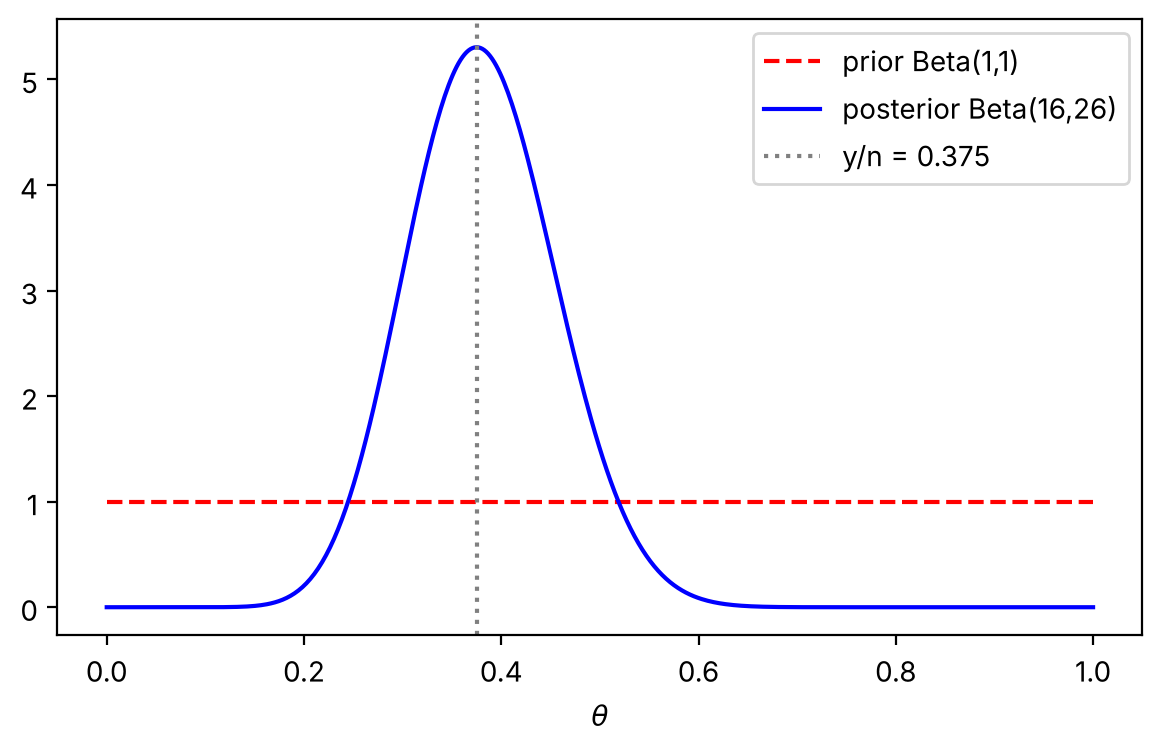

In [2]:
n, y = 40, 15
a, b = 1, 1
post = stats.beta(y + a, n - y + b)
grid = np.linspace(0, 1, 500)
plt.plot(grid, stats.beta(a, b).pdf(grid), "r--", label=f"prior Beta({a},{b})")
plt.plot(grid, post.pdf(grid), "b", label=f"posterior Beta({y+a},{n-y+b})")
plt.axvline(y/n, c="gray", ls=":", label="y/n = 0.375")
plt.xlabel(r"$\theta$"); plt.legend(); plt.show()

### 순차 업데이트 = 한 번에 업데이트

켤레라서 데이터를 나눠 넣어도 결과가 같다.

In [3]:
data = rng.binomial(1, 0.375, size=40)
a_seq, b_seq = 1, 1
for chunk in np.array_split(data, 4):
    a_seq += chunk.sum(); b_seq += len(chunk) - chunk.sum()
print("sequential :", (int(a_seq), int(b_seq)))
print("all at once:", (int(1 + data.sum()), int(1 + len(data) - data.sum())))

sequential : (15, 27)
all at once: (15, 27)


## 2. 몬테카를로로 로그오즈의 사후분포 구하기

θ를 사후분포에서 뽑고 $\eta=\log\frac{\theta}{1-\theta}$로 변환하기만 하면 된다.

E(eta | x)        ~ -0.497
95% HPD for eta   ~ (-1.143, 0.114)


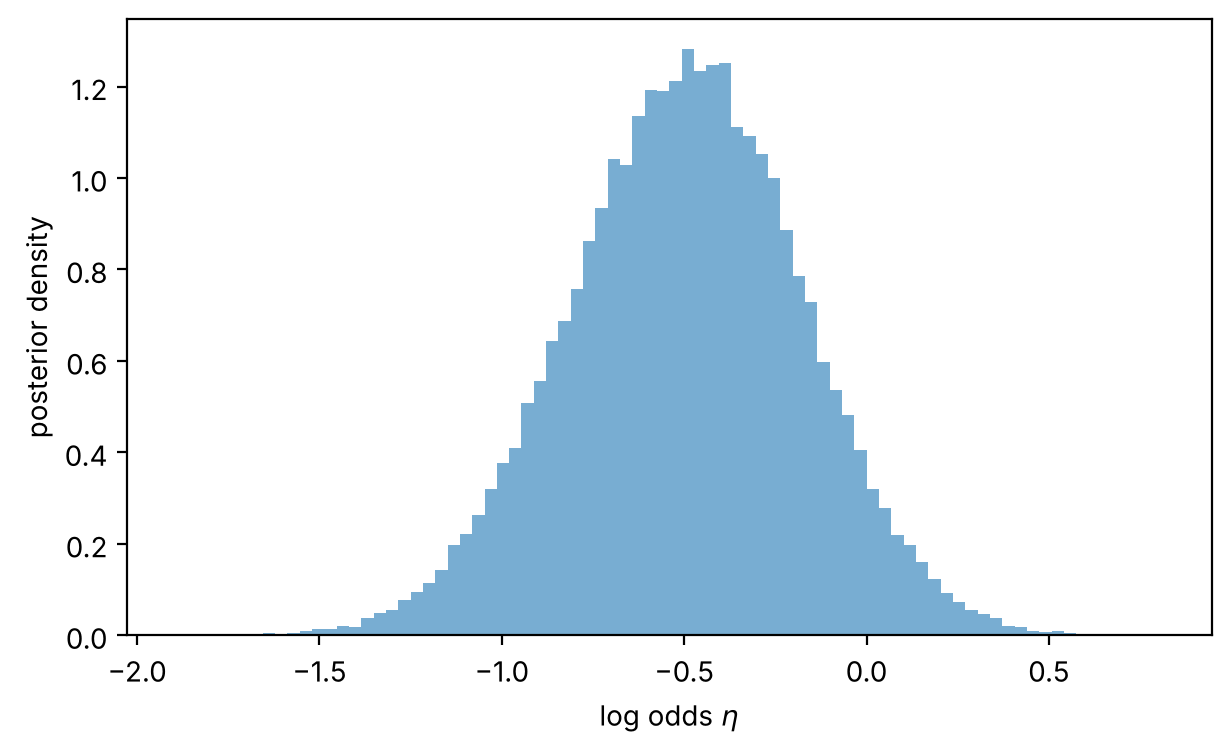

In [4]:
theta_s = post.rvs(50_000, random_state=rng)
eta_s = np.log(theta_s / (1 - theta_s))
print(f"E(eta | x)        ~ {eta_s.mean():.3f}")
print(f"95% HPD for eta   ~ ({hpd_sample(eta_s)[0]:.3f}, {hpd_sample(eta_s)[1]:.3f})")
plt.hist(eta_s, bins=80, density=True, alpha=0.6)
plt.xlabel(r"log odds $\eta$"); plt.ylabel("posterior density"); plt.show()

몬테카를로 오차는 $N$이 커질수록 $1/\sqrt N$ 속도로 줄어든다. 사후평균(정확값 16/42)으로 확인.

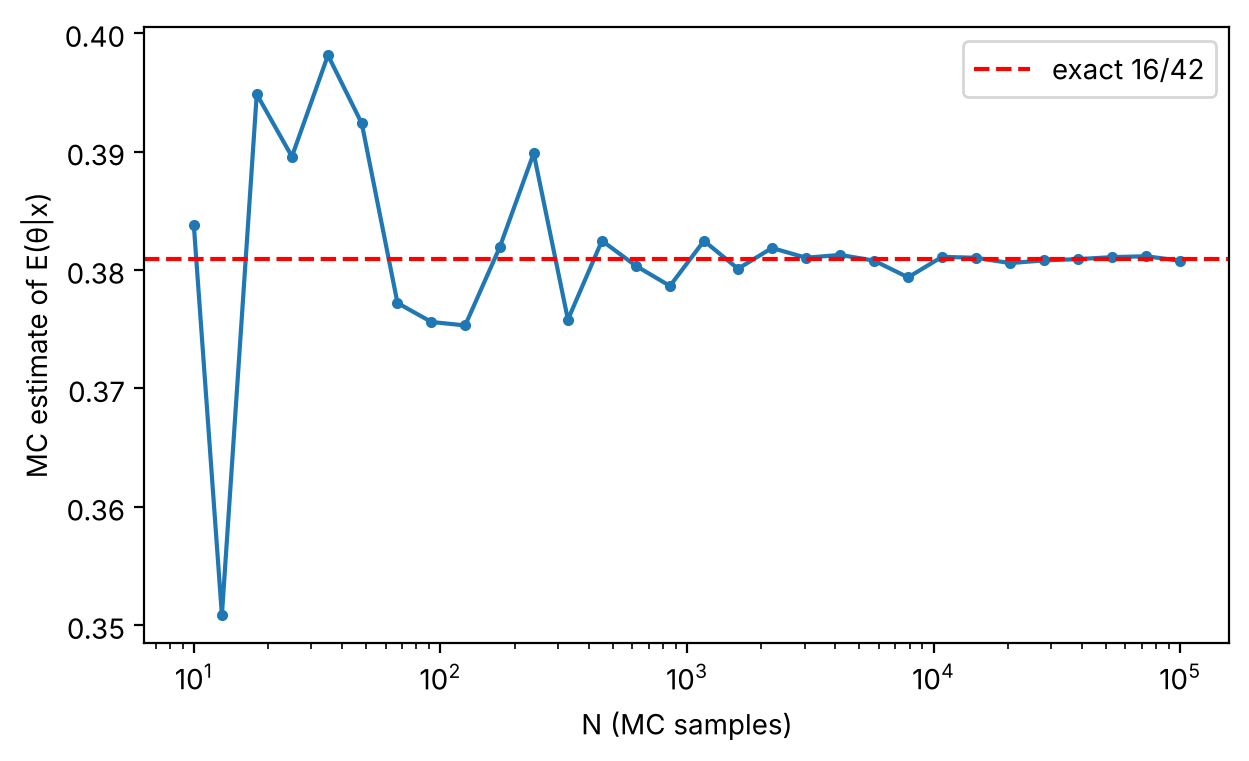

In [5]:
Ns = np.logspace(1, 5, 30).astype(int)
est = [post.rvs(N, random_state=rng).mean() for N in Ns]
plt.semilogx(Ns, est, "o-", ms=3); plt.axhline(16/42, c="r", ls="--", label="exact 16/42")
plt.xlabel("N (MC samples)"); plt.ylabel("MC estimate of E(θ|x)"); plt.legend(); plt.show()

## 3. 사후평균 = 표본평균과 사전평균의 가중평균

사전분포 $Beta(2,8)$ (사전 추측 0.2, 사전 표본 크기 10)로 고정하고, 관측 비율이 0.375로 일정할 때 $n$이 커지면?

In [6]:
a, b = 2, 8
for n_ in [0, 10, 40, 100, 1000]:
    y_ = 0.375 * n_
    w_data = n_ / (a + b + n_)
    post_mean = (y_ + a) / (a + b + n_)
    print(f"n={n_:5d}  data weight={w_data:.3f}  posterior mean={post_mean:.4f}")

n=    0  data weight=0.000  posterior mean=0.2000
n=   10  data weight=0.500  posterior mean=0.2875
n=   40  data weight=0.800  posterior mean=0.3400
n=  100  data weight=0.909  posterior mean=0.3591
n= 1000  data weight=0.990  posterior mean=0.3733


## 4. 예측분포: 다음 10번 중 성공 횟수

빈도론(θ̂=0.375 대입) vs 베이지안(베타-이항).

frequentist: mean=3.7500 var=2.3438
bayesian   : mean=3.8095 var=2.8519


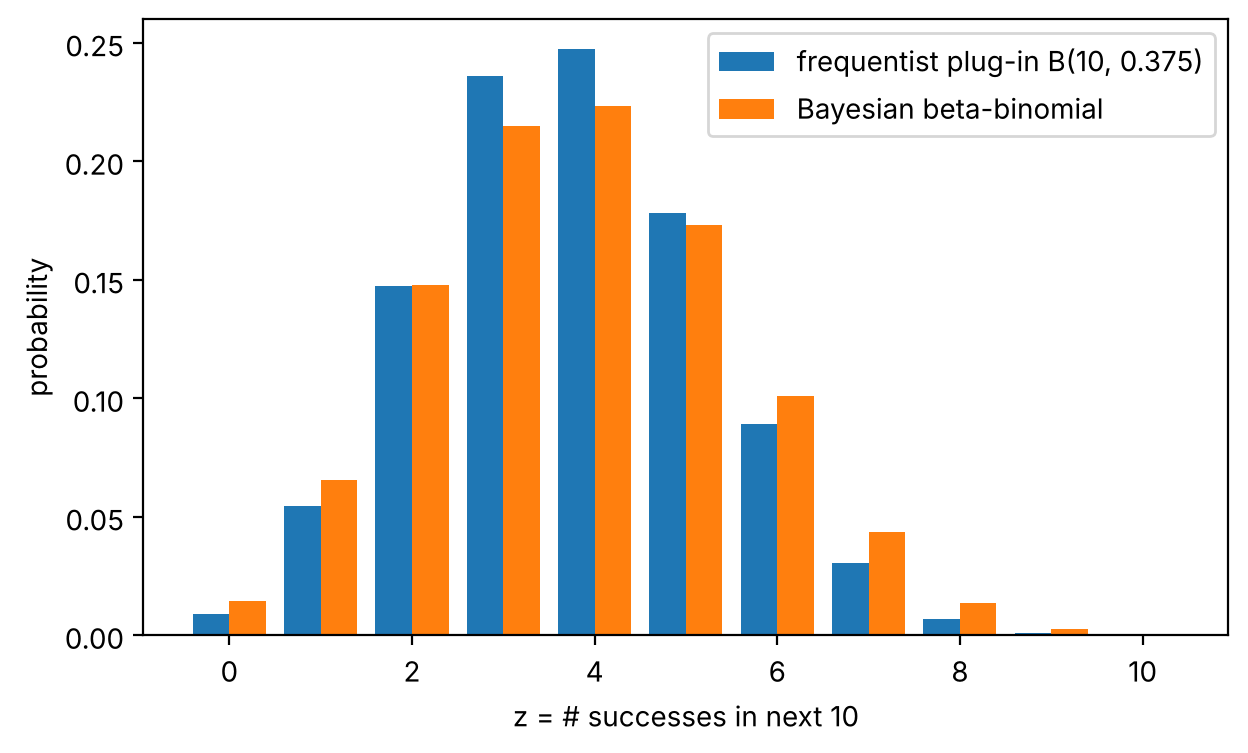

In [7]:
from scipy.special import comb, betaln
a, b, n, y, m = 1, 1, 40, 15, 10
z = np.arange(m + 1)

freq_pmf = stats.binom.pmf(z, m, y / n)
bayes_pmf = comb(m, z) * np.exp(betaln(a + y + z, b + n - y + m - z) - betaln(a + y, b + n - y))
# scipy 내장 베타-이항과 일치하는지 확인
assert np.allclose(bayes_pmf, stats.betabinom.pmf(z, m, a + y, b + n - y))

def mean_var(pmf):
    mu = (z * pmf).sum(); return mu, (z**2 * pmf).sum() - mu**2

print("frequentist: mean=%.4f var=%.4f" % mean_var(freq_pmf))
print("bayesian   : mean=%.4f var=%.4f" % mean_var(bayes_pmf))

w = 0.4
plt.bar(z - w/2, freq_pmf, w, label="frequentist plug-in B(10, 0.375)")
plt.bar(z + w/2, bayes_pmf, w, label="Bayesian beta-binomial")
plt.xlabel("z = # successes in next 10"); plt.ylabel("probability"); plt.legend(); plt.show()

베이지안 예측분포가 꼬리가 더 두껍다 → θ의 불확실성까지 반영했기 때문.

### 몬테카를로로 예측분포 근사 (두 가지 방법)

In [8]:
N = 100_000
theta_s = stats.beta(a + y, b + n - y).rvs(N, random_state=rng)

# 방법 1: f(z|x) ≈ (1/N) Σ f(z | θ_i)
mc1 = stats.binom.pmf(z[:, None], m, theta_s[None, :]).mean(axis=1)

# 방법 2: θ_i 뽑고 -> z_i ~ B(m, θ_i) 뽑기 -> z_i 들의 상대도수
z_s = rng.binomial(m, theta_s)
mc2 = np.bincount(z_s, minlength=m + 1) / N

print(" z | exact  | MC-1   | MC-2")
for zz in z:
    print(f"{zz:2d} | {bayes_pmf[zz]:.4f} | {mc1[zz]:.4f} | {mc2[zz]:.4f}")
print("MC-2 variance:", z_s.var().round(4))

 z | exact  | MC-1   | MC-2
 0 | 0.0144 | 0.0143 | 0.0135
 1 | 0.0657 | 0.0654 | 0.0651
 2 | 0.1478 | 0.1474 | 0.1463
 3 | 0.2149 | 0.2148 | 0.2124
 4 | 0.2233 | 0.2234 | 0.2261
 5 | 0.1729 | 0.1732 | 0.1741
 6 | 0.1009 | 0.1011 | 0.1022
 7 | 0.0437 | 0.0439 | 0.0435
 8 | 0.0135 | 0.0135 | 0.0140
 9 | 0.0027 | 0.0027 | 0.0024
10 | 0.0003 | 0.0003 | 0.0002
MC-2 variance: 2.8371


## 5. 신용구간 vs 신뢰구간 (n=10, x=2)

In [9]:
n, x = 10, 2
post = stats.beta(x + 1, n - x + 1)
hpd = hpd_sample(post.rvs(200_000, random_state=rng))
cp = (stats.beta.ppf(0.025, x, n - x + 1), stats.beta.ppf(0.975, x + 1, n - x))   # Clopper-Pearson
p_hat = x / n; se = np.sqrt(p_hat * (1 - p_hat) / n)
wald = (p_hat - 1.96 * se, p_hat + 1.96 * se)
for name, (l, u) in [("Bayesian 95% HPD", hpd), ("exact CI (Clopper-Pearson)", cp), ("Wald (asymptotic) CI", wald)]:
    print(f"{name:27s}: ({l:.3f}, {u:.3f})  width={u-l:.3f}")

Bayesian 95% HPD           : (0.043, 0.486)  width=0.443
exact CI (Clopper-Pearson) : (0.025, 0.556)  width=0.531
Wald (asymptotic) CI       : (-0.048, 0.448)  width=0.496


Wald 구간은 하한이 음수로 나온다. θ∈(0,1)인데도 정규근사 때문에 범위를 벗어나는 반면, 베이지안 구간은 항상 사후분포의 지지집합 안에 있다.

## 6. 두 비율 비교: 로그오즈비

그룹 1: 18명 중 12명, 그룹 2: 10명 중 8명이 "도움이 됐다"고 응답. 사전분포 $Beta(1,1)$.

posterior mean of xi : -0.562
95% HPD for xi       : (-2.305, 1.069)  -> 0 포함, 뚜렷한 차이 없음
P(theta1 < theta2|x) : 0.739


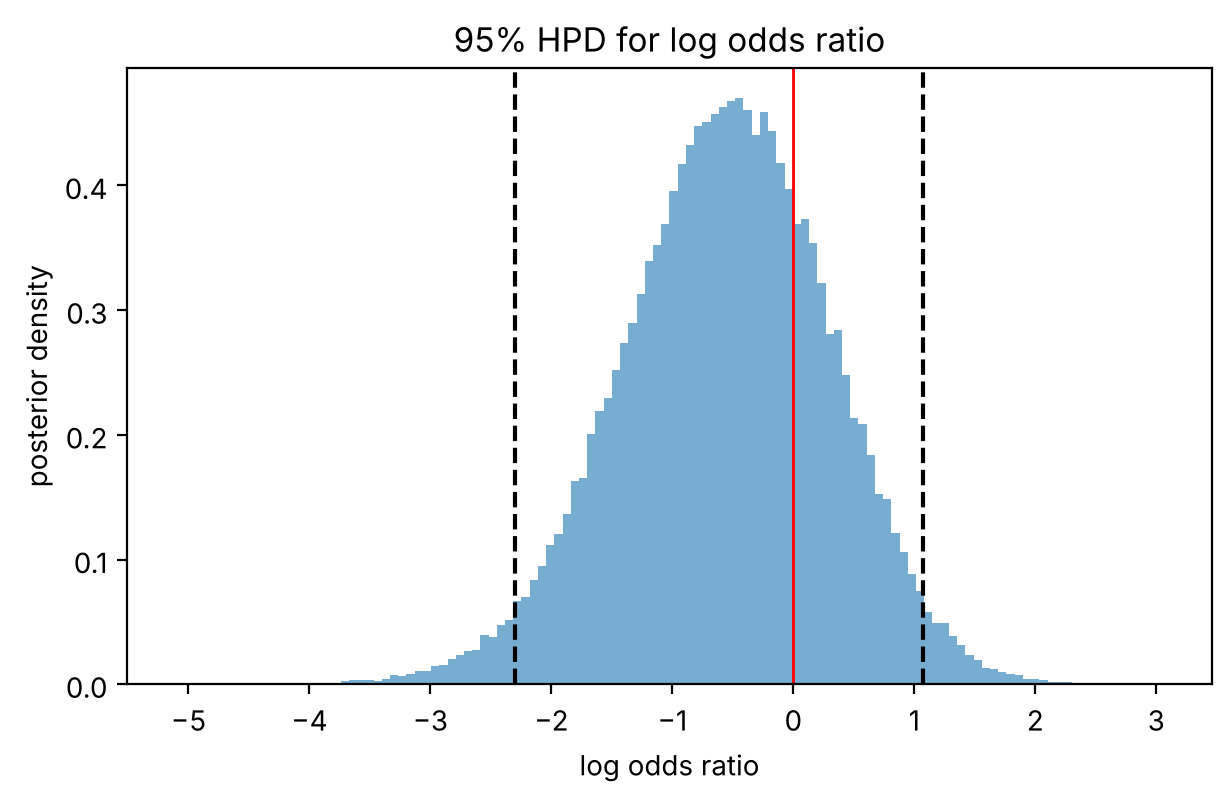

In [10]:
a = b = 1
n1, x1, n2, x2 = 18, 12, 10, 8
N = 100_000
t1 = stats.beta(a + x1, b + n1 - x1).rvs(N, random_state=rng)
t2 = stats.beta(a + x2, b + n2 - x2).rvs(N, random_state=rng)
xi = np.log(t1 / (1 - t1)) - np.log(t2 / (1 - t2))

lo, hi = hpd_sample(xi)
print(f"posterior mean of xi : {xi.mean():.3f}")
print(f"95% HPD for xi       : ({lo:.3f}, {hi:.3f})  -> 0 포함, 뚜렷한 차이 없음")
print(f"P(theta1 < theta2|x) : {(t1 < t2).mean():.3f}")

plt.hist(xi, bins=120, density=True, alpha=0.6)
for v in (lo, hi): plt.axvline(v, ls="--", c="k")
plt.axvline(0, c="r", lw=1)
plt.xlabel("log odds ratio"); plt.ylabel("posterior density"); plt.title("95% HPD for log odds ratio")
plt.show()

### 왜 차이 대신 로그오즈비인가

차이가 같아도 비율의 크기에 따라 의미가 완전히 다르다.

In [11]:
for p1, p2 in [(0.01, 0.001), (0.8, 0.809)]:
    lor = np.log(p1 / (1 - p1)) - np.log(p2 / (1 - p2))
    print(f"({p1}, {p2})  diff={p1 - p2:+.3f}  log odds ratio={lor:+.3f}")

(0.01, 0.001)  diff=+0.009  log odds ratio=+2.312
(0.8, 0.809)  diff=-0.009  log odds ratio=-0.057


## 7. 보충: 사후분포의 분모 $f(y)$의 정체

$f(y)=\int f(y\mid\theta)\pi(\theta)d\theta$를 수치적분, 닫힌 식, scipy 베타-이항 세 가지로 계산해 비교한다.

Beta(1,1), n=40, y=15 : [0.02439, 0.02439, 0.02439]  1/41 = 0.02439
Beta(2,8), n=40, y=15 : [0.026213, 0.026213, 0.026213]
Beta(1,1): f(y) for all y -> min/max = 0.02439 0.02439


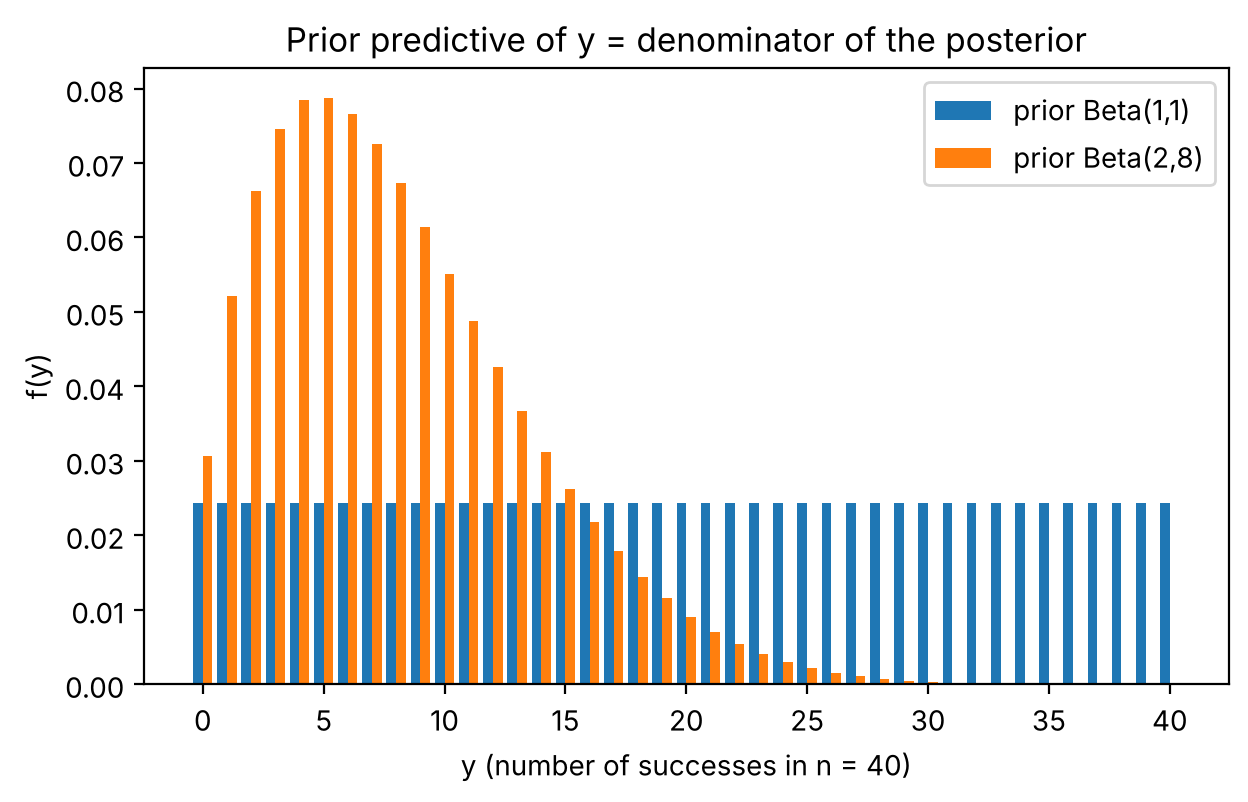

In [12]:
from scipy import integrate, special

def marginal_y(y, n, a, b):
    num, _ = integrate.quad(lambda t: stats.binom.pmf(y, n, t) * stats.beta(a, b).pdf(t), 0, 1)
    closed = float(special.comb(n, y) * np.exp(special.betaln(a + y, b + n - y) - special.betaln(a, b)))
    return num, closed, float(stats.betabinom.pmf(y, n, a, b))

print('Beta(1,1), n=40, y=15 :', [round(v, 6) for v in marginal_y(15, 40, 1, 1)], ' 1/41 =', round(1/41, 6))
print('Beta(2,8), n=40, y=15 :', [round(v, 6) for v in marginal_y(15, 40, 2, 8)])
pm_unif = stats.betabinom.pmf(np.arange(41), 40, 1, 1)
print('Beta(1,1): f(y) for all y -> min/max =', pm_unif.min().round(6), pm_unif.max().round(6))
pm_28 = stats.betabinom.pmf(np.arange(41), 40, 2, 8)

plt.bar(np.arange(41) - 0.2, pm_unif, 0.4, label='prior Beta(1,1)')
plt.bar(np.arange(41) + 0.2, pm_28, 0.4, label='prior Beta(2,8)')
plt.xlabel('y (number of successes in n = 40)'); plt.ylabel('f(y)'); plt.legend()
plt.title('Prior predictive of y = denominator of the posterior'); plt.show()

$Beta(1,1)$이면 $y$가 0부터 40까지 어디서든 확률이 똑같이 $1/41$이다. 사전분포에 따라 분모의 모양이 이렇게 달라진다.

## 8. 보충: 몬테카를로로 얻은 사후평균·분산을 정확값과 비교

$\theta\mid x\sim Beta(16,26)$, 로그오즈 $\eta$와 $1/\theta$.

E(eta|x)   : MC = -0.4992,  exact = -0.4977
Var(eta|x) : MC = 0.1036,  exact = 0.1037
E(1/theta|x): MC = 2.7358,  exact = 2.7333
1/E(theta|x)                 = 2.6250   <- 평균의 함수는 함수의 평균과 다르다


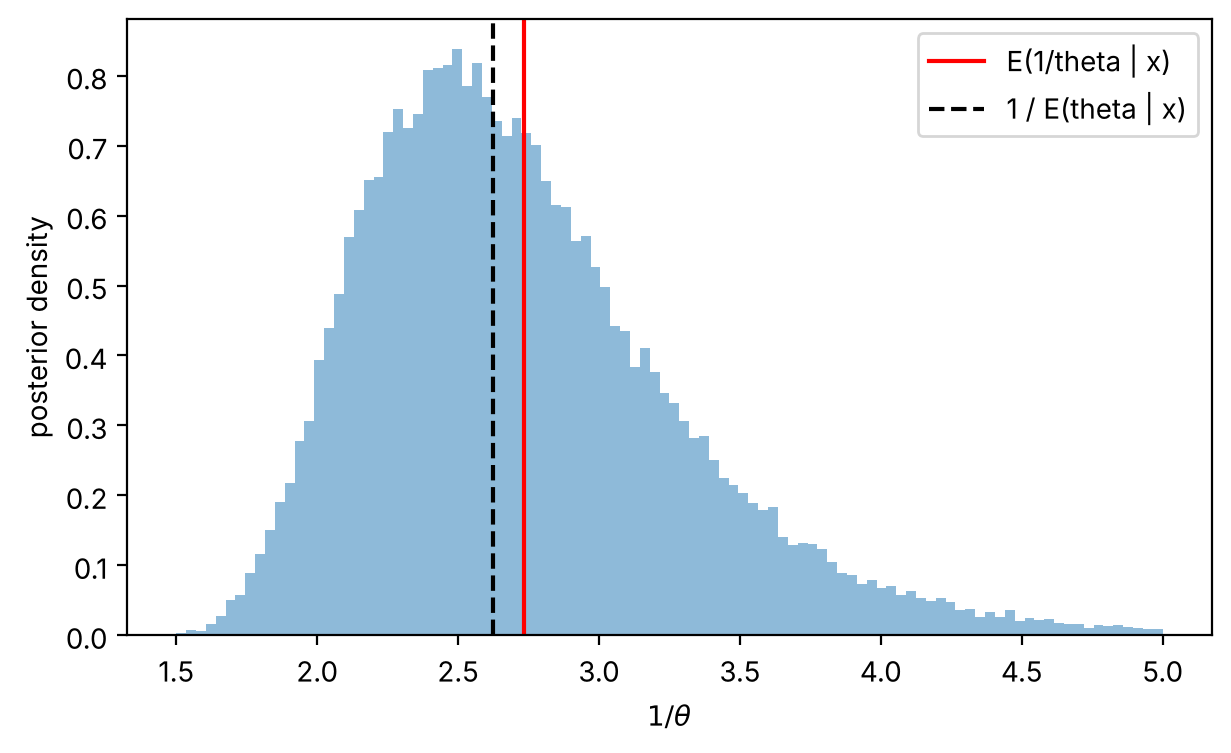

In [13]:
al, be = 16, 26
post40 = stats.beta(al, be)
N = 50_000
th = post40.rvs(N, random_state=rng)
eta = np.log(th / (1 - th))

E_eta_exact = special.digamma(al) - special.digamma(be)
V_eta_exact = special.polygamma(1, al) + special.polygamma(1, be)
print(f"E(eta|x)   : MC = {eta.mean():.4f},  exact = {E_eta_exact:.4f}")
print(f"Var(eta|x) : MC = {eta.var():.4f},  exact = {V_eta_exact:.4f}")

inv = 1 / th
print(f"E(1/theta|x): MC = {inv.mean():.4f},  exact = {(al+be-1)/(al-1):.4f}")
print(f"1/E(theta|x)                 = {1/post40.mean():.4f}   <- 평균의 함수는 함수의 평균과 다르다")

plt.hist(inv, bins=100, density=True, alpha=0.5, range=(1.5, 5))
plt.axvline((al + be - 1) / (al - 1), c='r', label='E(1/theta | x)')
plt.axvline(1 / post40.mean(), c='k', ls='--', label='1 / E(theta | x)')
plt.xlabel(r'$1/\theta$'); plt.ylabel('posterior density'); plt.legend(); plt.show()